In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Found 5742 files belonging to 4 classes.
Using 4594 files for training.
Found 5742 files belonging to 4 classes.
Using 1148 files for validation.
Found 1311 files belonging to 4 classes.
Class Names: ['glioma', 'meningioma', 'notumor', 'pituitary']


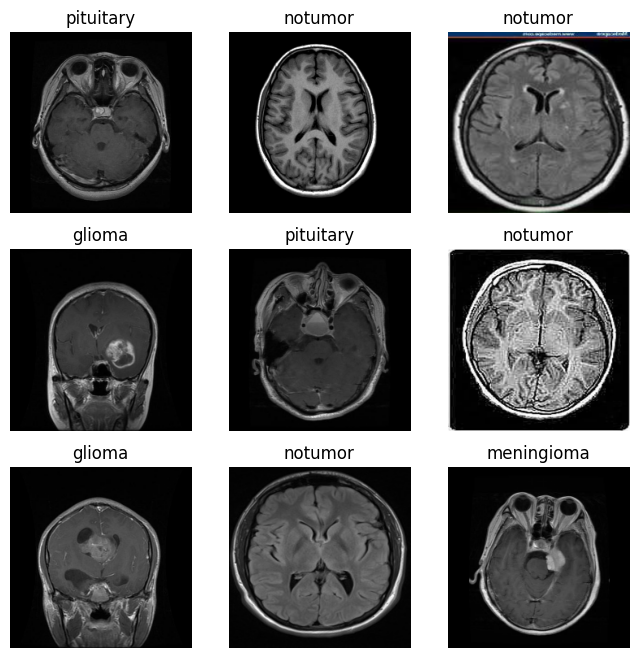

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

# Set dataset directories
train_dir = r"/content/drive/MyDrive/MIR Images/Training"
test_dir  = r"/content/drive/MyDrive/MIR Images/Testing"

# Set Image and Batch Sizes (VGG16 expects 224x224 images)
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# Split Training data into 80% Training and 20% Validation
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,       # 20% data for validation
    subset='training',
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset='validation',
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

# Load Testing data
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=False
)

# Check class names
class_names = train_ds.class_names
print("Class Names:", class_names)

# Normalize pixel values (0–255 → 0–1)
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

# Prefetch for faster performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Visualize sample images
plt.figure(figsize=(8, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

In [ ]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam

IMAGE_SHAPE = (224, 224, 3)

base_model = VGG16(
    include_top=False,           # Remove top fully connected layers
    weights='imagenet',          # Use pretrained ImageNet weights
    input_shape=IMAGE_SHAPE
)

#  Freeze Layers

for layer in base_model.layers:
    layer.trainable = False

# Unfreeze the last 3 layers
for layer in base_model.layers[-3:]:
    layer.trainable = True

#  Build the Complete Model
model = Sequential([
    base_model,                         # Pre-trained VGG16 base
    Flatten(),                          # Flatten to 1D
    Dropout(0.3),                       # Regularization
    Dense(128, activation='relu'),      # Hidden dense layer
    Dropout(0.2),                       # Additional regularization
    Dense(len(class_names), activation='softmax')  # Output layer for classification
])



model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['sparse_categorical_accuracy']
)

EPOCHS = 30
history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds
)


Epoch 1/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 85s 391ms/step - loss: 0.6403 - sparse_categorical_accuracy: 0.7432 - val_loss: 0.2546 - val_sparse_categorical_accuracy: 0.9085
Epoch 2/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 91s 227ms/step - loss: 0.2011 - sparse_categorical_accuracy: 0.9231 - val_loss: 0.2182 - val_sparse_categorical_accuracy: 0.9251
Epoch 3/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 32s 221ms/step - loss: 0.1273 - sparse_categorical_accuracy: 0.9535 - val_loss: 0.1976 - val_sparse_categorical_accuracy: 0.9321
Epoch 4/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 45s 248ms/step - loss: 0.0997 - sparse_categorical_accuracy: 0.9690 - val_loss: 0.2413 - val_sparse_categorical_accuracy: 0.9146
Epoch 5/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 32s 224ms/step - loss: 0.0560 - sparse_categorical_accuracy: 0.9790 - val_loss: 0.1318 - val_sparse_categorical_accuracy: 0.9547
Epoch 6/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 32s 218ms/step - loss: 0.0338 - sparse_categorical_accuracy: 0.9908 - val_loss: 0.2816 - val_sparse_categorical_acc

In [ ]:
# Save the entire trained model
model.save("model.h5")


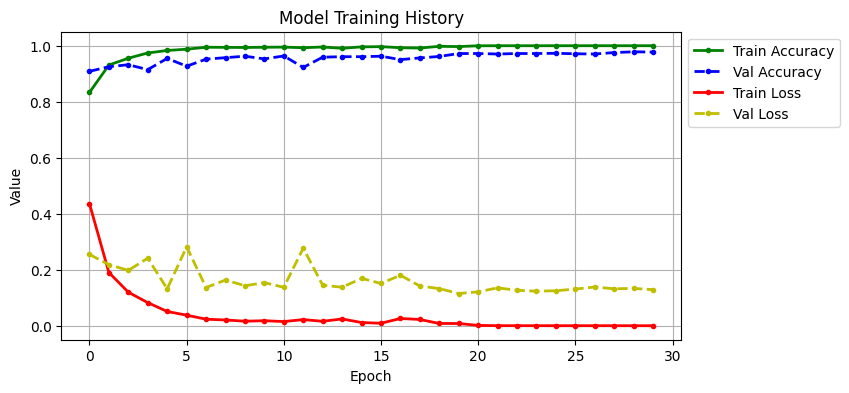

In [ ]:


#  Plot Training & Validation Accuracy and Loss
plt.figure(figsize=(8,4))
plt.grid(True)


plt.plot(history.history['sparse_categorical_accuracy'], '.-g', linewidth=2)
plt.plot(history.history['val_sparse_categorical_accuracy'], '.--b', linewidth=2)


plt.plot(history.history['loss'], '.-r', linewidth=2)
plt.plot(history.history['val_loss'], '.--y', linewidth=2)


plt.title('Model Training History')
plt.xlabel('Epoch')
plt.ylabel('Value')

plt.legend(
    ['Train Accuracy', 'Val Accuracy', 'Train Loss', 'Val Loss'],
    loc='upper left',
    bbox_to_anchor=(1, 1),

)

plt.show()

In [ ]:
from google.colab import files
files.download("model.h5")


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

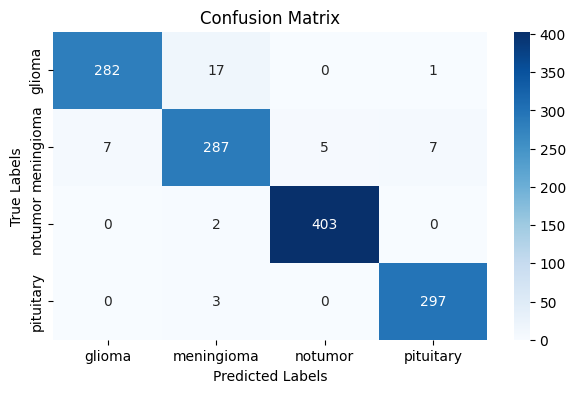

In [ ]:

# Model Evaluation

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images)
    y_true.extend(labels.numpy())                     # Actual labels
    y_pred.extend(np.argmax(preds, axis=1))           # Predicted labels

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(" Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

conf_matrix = confusion_matrix(y_true, y_pred)
print(" Confusion Matrix", conf_matrix)

plt.figure(figsize=(7, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model("model.h5")


In [ ]:
# --- 3D Feature Visualization ---

import tensorflow as tf
import numpy as np
from sklearn.decomposition import PCA
import plotly.express as px
import plotly.io as pio

pio.renderers.default = 'notebook_connected'


inputs = tf.keras.Input(shape=(224, 224, 3))
x = inputs
for layer in model.layers[:-2]:
    x = layer(x)
feature_extractor = tf.keras.Model(inputs=inputs, outputs=x)

sample_features = []
sample_labels = []

for images, lbls in test_ds.take(40):
    feats = feature_extractor.predict(images)
    sample_features.append(feats)
    sample_labels.extend(lbls.numpy())

features = np.concatenate(sample_features)
labels = np.array(sample_labels)

features_flat = features.reshape(features.shape[0], -1)

pca = PCA(n_components=3)
features_3d = pca.fit_transform(features_flat)

# --- Create 3D scatter plot ---
fig = px.scatter_3d(
    x=features_3d[:, 0],
    y=features_3d[:, 1],
    z=features_3d[:, 2],
    color=[class_names[i] for i in labels],
    hover_name=[f"Class: {class_names[i]}" for i in labels],
    title="3D VGG16 Feature Space Visualization",
    labels={'x': 'PCA 1', 'y': 'PCA 2', 'z': 'PCA 3'},
    width=700,
    height=500
)

fig.update_traces(marker=dict(size=5, opacity=0.8))
fig.update_layout(
    legend_title_text="Classes",
    margin=dict(l=0, r=130, b=0, t=40)
)

fig.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 